# Supplementary: SCEPTER spinup conditions by GCAM region

In [1]:
import os
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cmo
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.patches import Patch

SPINVERSION = "v4_repcells1"
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
savehere = REPO / "figures/supp"
(savehere / "panels").mkdir(parents=True, exist_ok=True)

# --- spinup conditions (one row per GCAM region)
df = pd.read_csv(
    f"s3://carbonplan-carbon-removal/ew-workflows-data/scepter/batch/spinup_gcam_{SPINVERSION}.csv"
)

# --- map of GCAM's 32 regions to project the spinup values onto
gcam_dir = (
    "s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated"
    "/one-cell-per-region/exe_central1p5/1.0-cropFraction"
)
dsag = xr.open_zarr(os.path.join(gcam_dir, "cropland+gcamRegions_time_1deg.zarr"))

reg_id_da  = dsag["reg_id"]
ocean_mask = dsag["cropland_area_by_region"] == 0

## Spinup stats

In [7]:
# --- mean, median, and range across the 32 GCAM regions
stat_vars = {
    "qrun":         "Water infiltration (m/yr)",
    "mat":          "Mean annual temperature (°C)",
    "soilmoisture": "Soil moisture (m³/m³)",
    "cec":          "Cation exchange capacity (cmolc/kg)",
    "tph":          "Porewater pH",
    "tsoilco2":     "Soil CO₂ (ppmv)",
    "tsom":         "Soil organic matter (wt %)",
    "tec":          "Exchangeable acidity (% CEC)",
}

stats = pd.DataFrame({
    label: (10**df[var] * 1e6 if var == "tsoilco2" else df[var])   # log10(atm) -> ppmv
           .agg(["mean", "median", "min", "max"])
    for var, label in stat_vars.items()
}).T

with pd.option_context("display.float_format", "{:,.2f}".format):
    print(stats)

                                        mean   median      min       max
Water infiltration (m/yr)               1.20     1.14     0.49      2.54
Mean annual temperature (°C)           18.10    18.19     4.52     28.68
Soil moisture (m³/m³)                   0.29     0.30     0.16      0.36
Cation exchange capacity (cmolc/kg)    21.19    20.20     9.10     39.50
Porewater pH                            6.16     6.20     5.40      6.80
Soil CO₂ (ppmv)                     6,424.60 6,470.20 2,925.11 10,804.53
Soil organic matter (wt %)              2.56     2.21     0.99      6.58
Exchangeable acidity (% CEC)           30.31    28.00    10.00     75.00


In [2]:
# ---------------------------------------
# [ aesthetics ]
lon_min, lon_max, lat_min, lat_max = -181, 181, -57, 86
coast_lsize, borders_lsize = 0.4, 0.25
fs_label, fs_tick, fs_mainTitle = 12, 10, 15
n_bins = 14
# ---------------------------------------


def region_map(var, transform=None):
    """Paint each GCAM region with its spinup value."""
    vals = df.set_index("reg_id")[var].to_dict()
    arr = np.vectorize(lambda r: vals.get(int(r), np.nan))(reg_id_da.values)
    if transform is not None:
        arr = transform(arr)
    return xr.DataArray(arr, coords=reg_id_da.coords, dims=reg_id_da.dims).where(~ocean_mask)


def panel_grid(specs, suptitle=None, figsize=(13.5, 9.5)):
    """2x2 blocks of (histogram / colorbar / map), one block per variable."""
    fig = plt.figure(figsize=figsize)
    outer = fig.add_gridspec(2, 2, hspace=0.22, wspace=0.12)
    blocks = []

    for i, sp in enumerate(specs):
        sub = outer[i // 2, i % 2].subgridspec(3, 1, height_ratios=[0.34, 0.14, 1.0], hspace=0.03)
        ax_h = fig.add_subplot(sub[0])
        ax_c = fig.add_subplot(sub[1])
        ax_m = fig.add_subplot(sub[2], projection=ccrs.Robinson())
        ax_m.set_anchor("N")   # hug the colorbar rather than centering in the cell

        vmin, vmax = sp["clim"]
        cmap, norm = sp["cmap"], plt.Normalize(*sp["clim"])

        region_map(sp["var"], sp.get("transform")).plot(
            ax=ax_m, transform=ccrs.PlateCarree(), cmap=cmap,
            vmin=vmin, vmax=vmax, add_colorbar=False,
        )
        ax_m.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
        ax_m.coastlines(linewidth=coast_lsize)
        ax_m.add_feature(cfeature.BORDERS, linewidth=borders_lsize)
        ax_m.set_title("")

        # colorbar doubles as the histogram's x-axis
        cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap),
                          cax=ax_c, orientation="horizontal")
        cb.ax.tick_params(labelsize=fs_tick)
        cb.outline.set_linewidth(0.5)

        # histogram on the colorbar's scale, bars tinted by their own bin value
        vals = df[sp["var"]].dropna().values
        if sp.get("transform"):
            vals = sp["transform"](vals)
        edges = np.linspace(vmin, vmax, n_bins + 1)
        counts, _ = np.histogram(vals, bins=edges)
        ax_h.bar(edges[:-1], counts, width=np.diff(edges), align="edge",
                 color=cmap(norm((edges[:-1] + edges[1:]) / 2)),
                 edgecolor="0.3", linewidth=0.5)
        ax_h.set_xlim(vmin, vmax)
        ax_h.set_xticks([])
        ax_h.set_ylabel("n regions", fontsize=fs_tick)
        ax_h.yaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=3))
        ax_h.tick_params(labelsize=fs_tick)
        ax_h.spines[["top", "right"]].set_visible(False)
        ax_h.set_title(sp["label"], fontsize=fs_label)

        blocks.append((ax_h, ax_c, ax_m))

    # match histogram + colorbar width to the aspect-locked map beneath them
    fig.canvas.draw()
    for ax_h, ax_c, ax_m in blocks:
        bm = ax_m.get_position()
        bh, bc = ax_h.get_position(), ax_c.get_position()
        ax_h.set_position([bm.x0, bh.y0, bm.width, bh.height])
        # thin bar pinned to the top of its cell, the rest left for tick labels
        ax_c.set_position([bm.x0, bc.y1 - 0.3 * bc.height, bm.width, 0.3 * bc.height])

    if suptitle:
        fig.suptitle(suptitle, fontsize=fs_mainTitle, y=0.95)
    return fig

## Figure — the 32 GCAM regions
The domain the spinups cover: each region painted by its `reg_id`, with cells that hold no
cropland masked out.

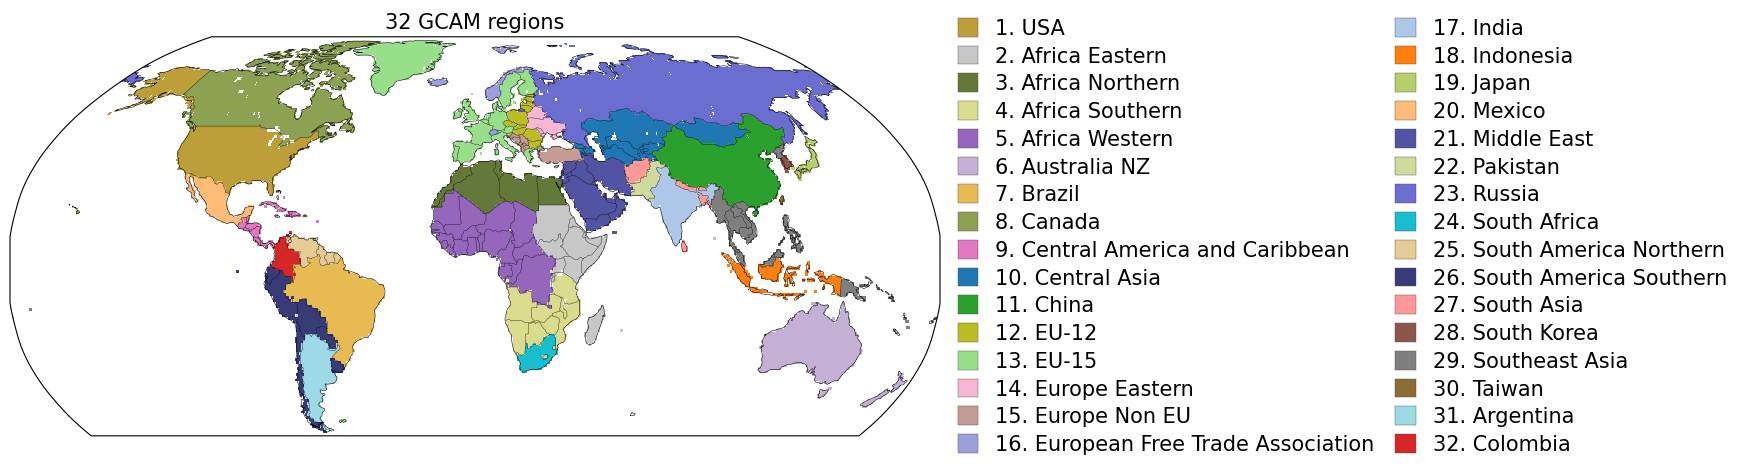

In [3]:
# ———————————————————————————————————
SAVE_ON  = False
# ———————————————————————————————————
# 32 categorical colors, shuffled so neighboring regions rarely share a hue
colors = list(plt.get_cmap("tab20").colors + plt.get_cmap("tab20b").colors)[:32]
np.random.seed(42)
np.random.shuffle(colors)
reg_cmap = mcolors.ListedColormap(colors)
reg_norm = mcolors.BoundaryNorm(np.arange(0.5, 33.5, 1), reg_cmap.N)

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

reg_id_da.where(~ocean_mask).plot(
    ax=ax, transform=ccrs.PlateCarree(),
    cmap=reg_cmap, norm=reg_norm, add_colorbar=False,
)
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
ax.coastlines(linewidth=coast_lsize)
ax.add_feature(cfeature.BORDERS, linewidth=borders_lsize)
ax.set_title("32 GCAM regions", fontsize=fs_mainTitle)

# --- legend of region names, two columns to the right of the map
handles = [
    Patch(facecolor=reg_cmap(reg_norm(rid)), edgecolor="0.3", linewidth=0.3,
          label=f"{rid}. {name.replace('_', ' ')}")
    for rid, name in df[["reg_id", "region"]].sort_values("reg_id").itertuples(index=False)
]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.01, 0.5),
          ncol=2, fontsize=fs_tick + 5, frameon=False, handlelength=1.0,
          handleheight=1.0, labelspacing=0.35, columnspacing=1.0, borderaxespad=0)

if SAVE_ON:
    fig.savefig(os.path.join(savehere, "panels", "gcam-regions.png"),
                dpi=300, bbox_inches="tight", transparent=False)
plt.show()
plt.close();

## Figure — cropland fraction
How much of each cell is cropland (`cropland_frac`).

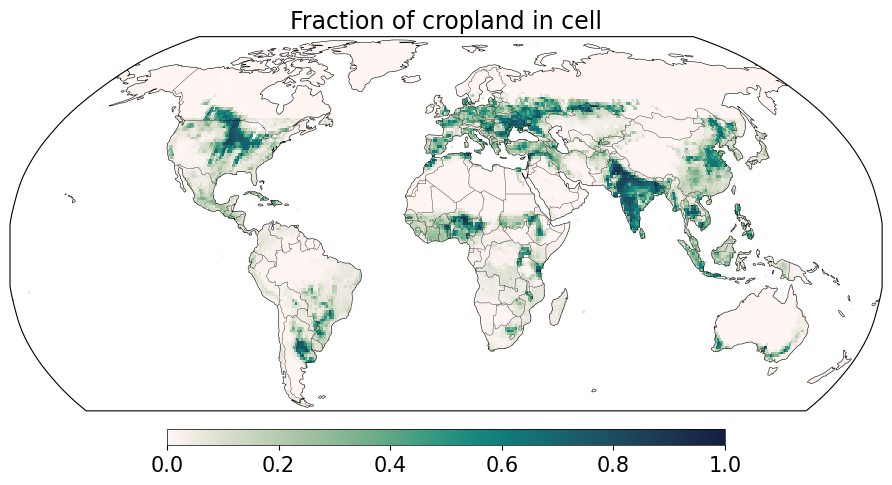

In [4]:
# ———————————————————————————————————
SAVE_ON  = False
# ———————————————————————————————————
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

im = dsag["cropland_frac"].where(~ocean_mask).plot(
    ax=ax, transform=ccrs.PlateCarree(),
    cmap=cmo.cm.tempo, vmin=0, vmax=1,
    add_colorbar=True,
    cbar_kwargs=dict(orientation="horizontal", pad=0.04, shrink=0.6, aspect=35, label=""),
)
cb = im.colorbar
cb.ax.tick_params(labelsize=fs_tick+5)
cb.outline.set_linewidth(0.5)

ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
ax.coastlines(linewidth=coast_lsize)
ax.add_feature(cfeature.BORDERS, linewidth=borders_lsize)
ax.set_title("Fraction of cropland in cell", fontsize=fs_mainTitle+2)

if SAVE_ON:
    fig.savefig(os.path.join(savehere, "panels", "cropland-fraction.png"),
                dpi=300, bbox_inches="tight", transparent=False)
plt.show()
plt.close();

## Figure — spinup forcings
Mean annual temperature (`mat`), water infiltration (`qrun`), soil moisture
(`soilmoisture`), and cation exchange capacity (`cec`).

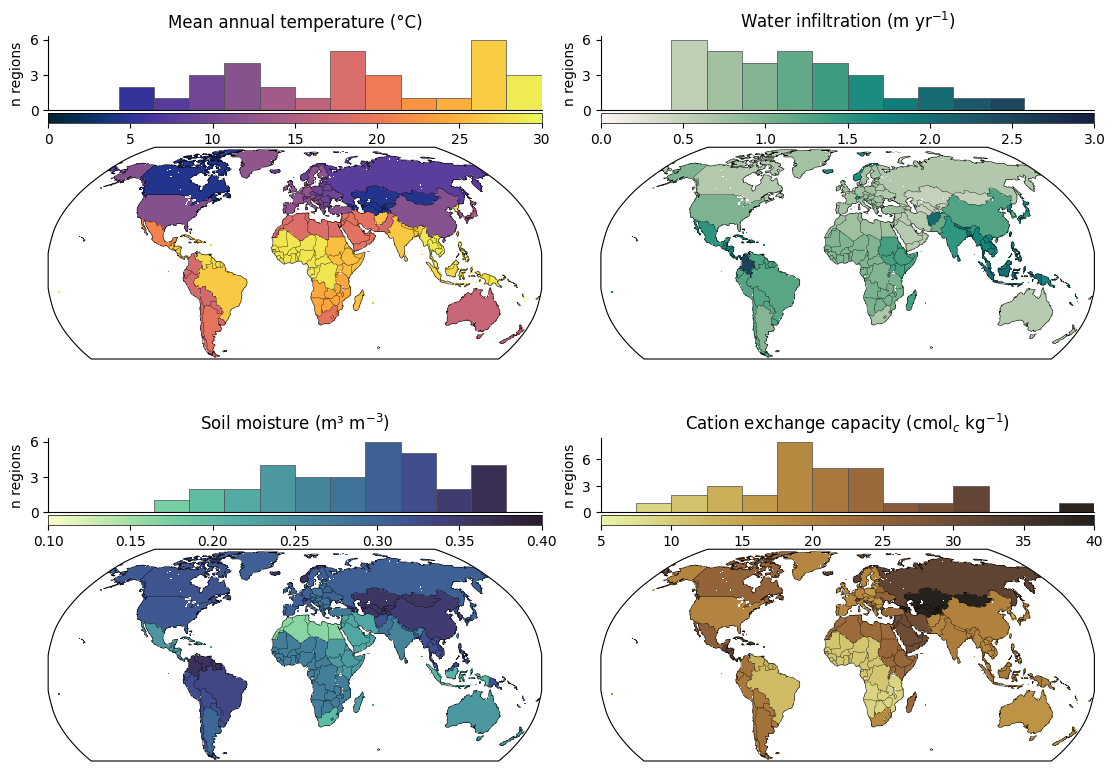

In [5]:
# ———————————————————————————————————
SAVE_ON  = False
# ———————————————————————————————————
forcing = [
    dict(var="mat",          label="Mean annual temperature (°C)",     cmap=cmo.cm.thermal, clim=(0, 30)),
    dict(var="qrun",         label="Water infiltration (m yr$^{-1}$)", cmap=cmo.cm.tempo,   clim=(0, 3)),
    dict(var="soilmoisture", label="Soil moisture (m³ m$^{-3}$)",      cmap=cmo.cm.deep,    clim=(0.1, 0.4)),
    dict(var="cec",          label="Cation exchange capacity (cmol$_c$ kg$^{-1}$)",
         cmap=cmo.cm.turbid, clim=(5, 40)),
]

fig = panel_grid(forcing, f"")
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "panels", "spinup-forcings.png"),
                dpi=300, bbox_inches="tight", transparent=False)
plt.show()
plt.close();

## Figure — spinup targets
Soil CO₂ (`tsoilco2`, stored as log₁₀ atm), porewater pH (`tph`), soil organic matter
(`tsom`), and exchangeable acidity (`tec`).

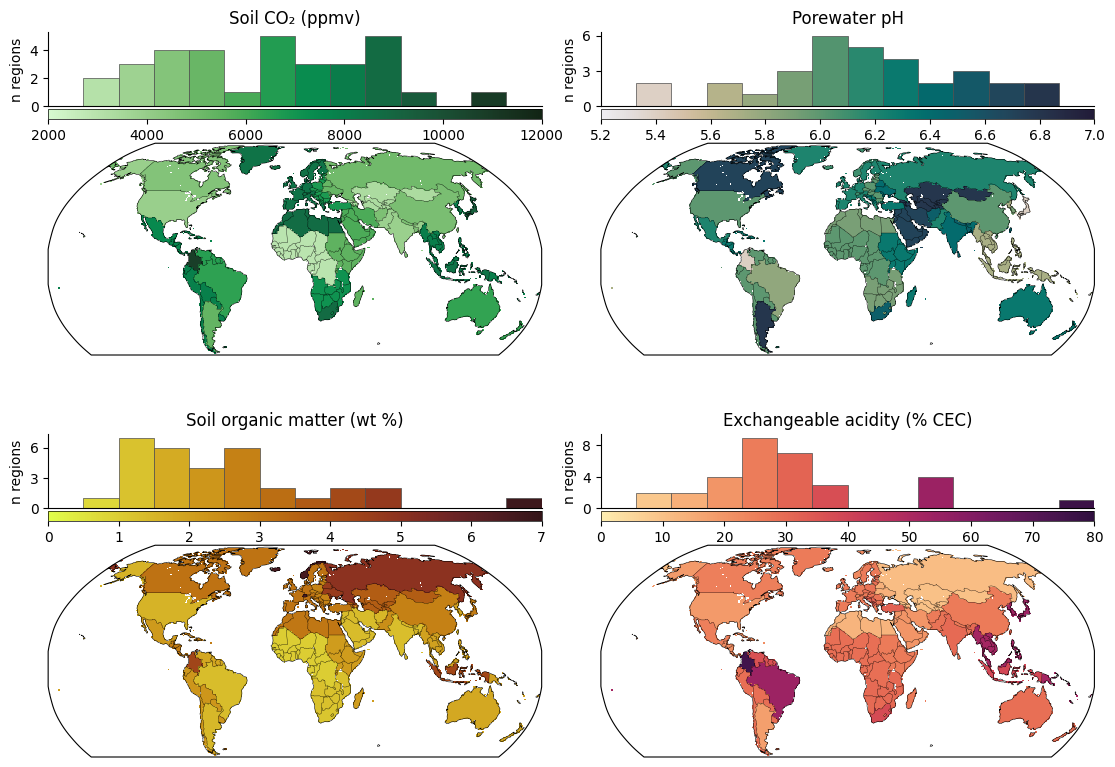

In [6]:
# ———————————————————————————————————
SAVE_ON  = False
# ———————————————————————————————————
targets = [
    dict(var="tsoilco2", label="Soil CO₂ (ppmv)", cmap=cmo.cm.algae, clim=(2000, 12000),
         transform=lambda x: 10**x * 1e6),                       # log10(atm) -> ppmv
    dict(var="tph",  label="Porewater pH",                cmap=cmo.cm.rain,    clim=(5.2, 7.0)),
    dict(var="tsom", label="Soil organic matter (wt %)",  cmap=cmo.cm.solar_r, clim=(0, 7)),
    dict(var="tec",  label="Exchangeable acidity (% CEC)", cmap=cmo.cm.matter, clim=(0, 80)),
]

fig = panel_grid(targets, f"")
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "panels", "spinup-targets.png"),
                dpi=300, bbox_inches="tight", transparent=False)
plt.show()
plt.close();

In [ ]:
# ---